# Задача 4.8
# Последовательный выбор двух точек на отрезке

## Условие
Сначала равномерно выбирают $x$ на $[a,b]$, затем равномерно $y$ на $[a,x]$. A — вторая точка ближе к $b$, чем первая к $a$; B — расстояние между точками меньше половины длины исходного отрезка; C — первая точка ближе ко второй, чем к $b$. Провести $150000$ опытов.

## Теория с нуля и решение вручную
### 1. Нормировка и условная плотность
Пусть $L=b-a>0$, $X=(x-a)/L$, $Y=(y-a)/L$. Тогда $0\le Y\le X\le1$. При фиксированном $X=t$ величина $Y$ равномерна на $[0,t]$, поэтому условная вероятность области равна длине подходящей части этого отрезка, делённой на $t$.
Плотность $X$ равна 1, условная плотность $Y$ равна $1/t$. Совместная плотность:
$$f_{X,Y}(t,s)=\frac1t,\quad0<s<t<1.$$
Она **не постоянна**: делить площади в треугольнике нельзя. Для вероятности сначала вычисляем условную долю при $X=t$, затем усредняем по $t$: $P(E)=\int_0^1P(E\mid X=t)\,dt$. Точка $t=0$ имеет вероятность ноль и интегралу не мешает.

### 2. Событие A
Расстояния: до правого конца от $Y$ равно $1-Y$, от $X$ до левого — $X$. Условие $1-Y<X$ равносильно $Y>1-X$. Оно возможно только при $X>1/2$:
$$P(A)=\int_{1/2}^1\frac{t-(1-t)}t\,dt=\int_{1/2}^1\left(2-\frac1t\right)dt=1-\ln2.$$
Здесь $\int dt/t=\ln t$, а $\ln1=0$, $\ln(1/2)=-\ln2$.

### 3. Событие B
Расстояние $X-Y<1/2$. При $X\le1/2$ подходит весь отрезок выбора $Y$. При $X>1/2$ подходят $Y>X-1/2$, то есть участок длины $1/2$:
$$P(B)=\int_0^{1/2}1\,dt+\int_{1/2}^1\frac{1}{2t}\,dt=\frac{1+\ln2}{2}.$$

### 4. Событие C
Условие $X-Y<1-X$ равносильно $Y>2X-1$. При $X\le1/2$ оно выполняется всегда, а дальше подходящая длина равна $1-X$:
$$P(C)=\frac12+\int_{1/2}^1\frac{1-t}{t}\,dt=\ln2.$$
Ответы не зависят от $a,b$: мы одинаково масштабировали все расстояния.

### 5. Переход к коду
Берём независимые $U,V\sim U(0,1)$, полагаем $X=U$, $Y=UV$. При данном $U=t$ произведение $tV$ действительно равномерно на $[0,t]$. Генерировать две независимые точки и сортировать их здесь нельзя: это другая модель с другой плотностью.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

A: вторая ближе к правому концу: успехов 45571, знаменатель 150000
  частота = 0.30380667; ориентир 95%: [0.30147925; 0.30613408]
  теория = 0.30685282; разность = -0.00304615


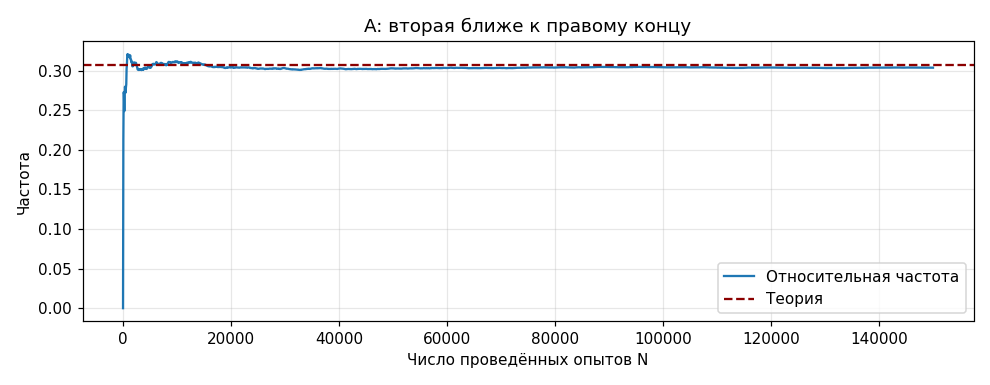

B: расстояние меньше половины отрезка: успехов 127190, знаменатель 150000
  частота = 0.84793333; ориентир 95%: [0.84611611; 0.84975056]
  теория = 0.84657359; разность = +0.00135974


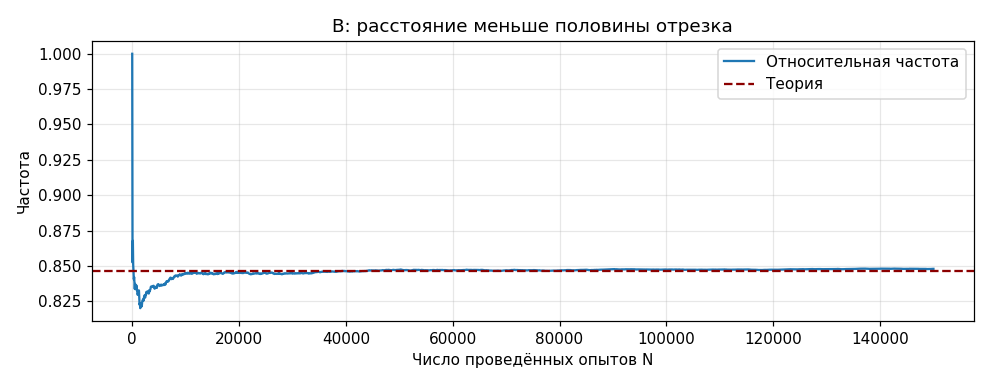

C: первая ближе ко второй: успехов 104239, знаменатель 150000
  частота = 0.69492667; ориентир 95%: [0.69259653; 0.69725681]
  теория = 0.69314718; разность = +0.00177949


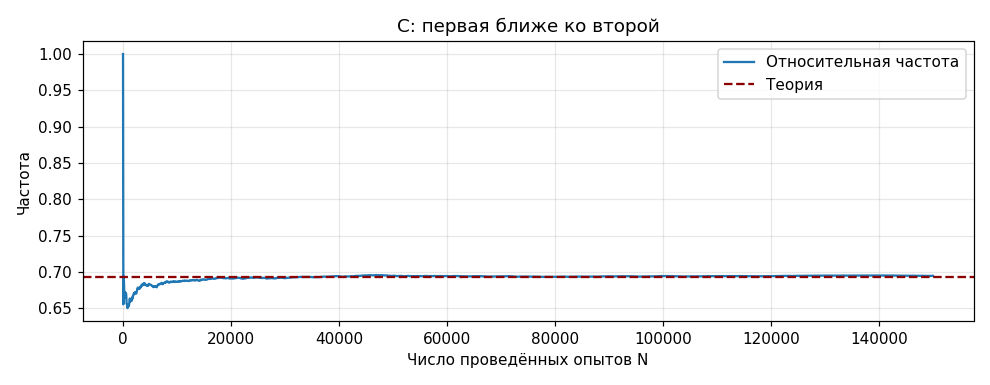

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
X = rng.random(N)
Y = X*rng.random(N)
A = 1-Y < X
B = X-Y < 0.5
C = X-Y < 1-X
report(A, 'A: вторая ближе к правому концу', 1-math.log(2))
report(B, 'B: расстояние меньше половины отрезка', (1+math.log(2))/2)
report(C, 'C: первая ближе ко второй', math.log(2))
